# Week 4 — Day 5: Data Analysis Capstone

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Salary_Dataset_with_Extra_Features.csv")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 22770
Number of Columns: 8


In [9]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Rating', 'Company Name', 'Job Title', 'Salary', 'Salaries Reported', 'Location', 'Employment Status', 'Job Roles']


In [10]:

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22770 entries, 0 to 22769
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Rating             22770 non-null  float64
 1   Company Name       22769 non-null  object 
 2   Job Title          22770 non-null  object 
 3   Salary             22770 non-null  int64  
 4   Salaries Reported  22770 non-null  int64  
 5   Location           22770 non-null  object 
 6   Employment Status  22770 non-null  object 
 7   Job Roles          22770 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 1.4+ MB


In [11]:
print("\nStatistical Summary:")
display(df.describe(include="all"))


Statistical Summary:


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
count,22770.000000,22769,22770,2.277000e+04,22770.000000,22770,22770,22770
unique,NaN,11260,1080,NaN,NaN,10,4,11
top,NaN,Tata Consultancy Services,Software Development Engineer,NaN,NaN,Bangalore,Full Time,SDE
freq,NaN,271,2351,NaN,NaN,8264,20083,8183
mean,3.918213,NaN,NaN,6.953872e+05,1.855775,NaN,NaN,NaN
std,0.519675,NaN,NaN,8.843990e+05,6.823668,NaN,NaN,NaN
min,1.000000,NaN,NaN,2.112000e+03,1.000000,NaN,NaN,NaN
25%,3.700000,NaN,NaN,3.000000e+05,1.000000,NaN,NaN,NaN
50%,3.900000,NaN,NaN,5.000000e+05,1.000000,NaN,NaN,NaN
75%,4.200000,NaN,NaN,9.000000e+05,1.000000,NaN,NaN,NaN


In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Rating               0
Company Name         1
Job Title            0
Salary               0
Salaries Reported    0
Location             0
Employment Status    0
Job Roles            0
dtype: int64

Duplicate Rows:
0


In [13]:
# Display rows containing missing values

missing_rows = df[df.isnull().any(axis=1)]

print("Rows containing missing values:")
display(missing_rows)

Rows containing missing values:


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
13760,4.0,NaN,Software Development Engineer,1188000,1,Bangalore,Full Time,SDE


In [14]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
Rating               float64
Company Name          object
Job Title             object
Salary                 int64
Salaries Reported      int64
Location              object
Employment Status     object
Job Roles             object
dtype: object


In [15]:
print("Salary Statistics:")
print(df["Salary"].describe())

Salary Statistics:
count    2.277000e+04
mean     6.953872e+05
std      8.843990e+05
min      2.112000e+03
25%      3.000000e+05
50%      5.000000e+05
75%      9.000000e+05
max      9.000000e+07
Name: Salary, dtype: float64


In [16]:
# Create a copy of the original dataset
df_clean = df.copy()

# Handle missing company names
df_clean["Company Name"] = df_clean["Company Name"].fillna("Unknown")

# Verify missing values
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDataset shape:", df_clean.shape)

Missing values after cleaning:
Rating               0
Company Name         0
Job Title            0
Salary               0
Salaries Reported    0
Location             0
Employment Status    0
Job Roles            0
dtype: int64

Dataset shape: (22770, 8)


In [17]:
# Calculate quartiles
Q1 = df_clean["Salary"].quantile(0.25)
Q3 = df_clean["Salary"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify outliers
outliers = df_clean[
    (df_clean["Salary"] < lower_bound) |
    (df_clean["Salary"] > upper_bound)
]

print("\nNumber of outliers:", len(outliers))
print("Percentage of outliers:", round(len(outliers) / len(df_clean) * 100, 2), "%")

Q1: 300000.0
Q3: 900000.0
IQR: 600000.0
Lower Bound: -600000.0
Upper Bound: 1800000.0

Number of outliers: 1156
Percentage of outliers: 5.08 %


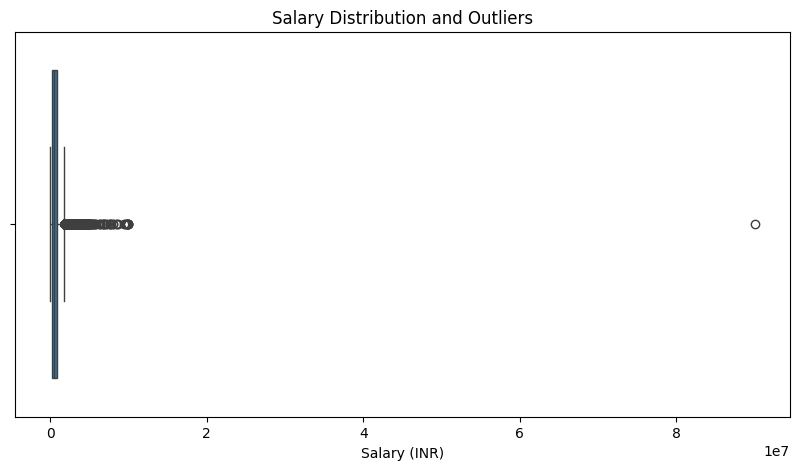

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["Salary"])

plt.title("Salary Distribution and Outliers")
plt.xlabel("Salary (INR)")

plt.show()

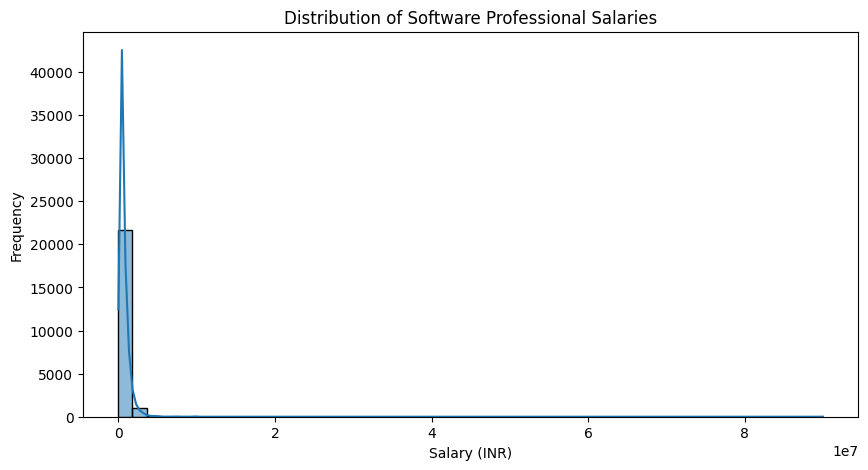

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(df_clean["Salary"], bins=50, kde=True)

plt.title("Distribution of Software Professional Salaries")
plt.xlabel("Salary (INR)")
plt.ylabel("Frequency")

plt.show()

In [21]:
# Salary Distribution Analysis

print("SALARY ANALYSIS")

print("Mean Salary:", df_clean["Salary"].mean())

print("Median Salary:", df_clean["Salary"].median())

print("Minimum Salary:", df_clean["Salary"].min())

print("Maximum Salary:", df_clean["Salary"].max())

print("Standard Deviation:", df_clean["Salary"].std())

print("25th Percentile:", df_clean["Salary"].quantile(0.25))

print("75th Percentile:", df_clean["Salary"].quantile(0.75))

SALARY ANALYSIS
Mean Salary: 695387.2112428634
Median Salary: 500000.0
Minimum Salary: 2112
Maximum Salary: 90000000
Standard Deviation: 884399.0136761833
25th Percentile: 300000.0
75th Percentile: 900000.0


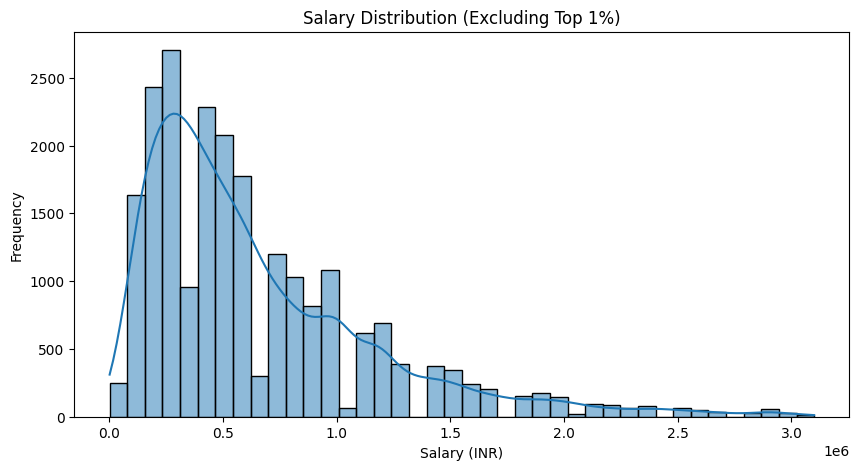

In [22]:
# Calculate 99th percentile

salary_99 = df_clean["Salary"].quantile(0.99)

# Filter data for visualization

salary_filtered = df_clean[df_clean["Salary"] <= salary_99]

plt.figure(figsize=(10, 5))

sns.histplot(salary_filtered["Salary"], bins=40, kde=True)

plt.title("Salary Distribution (Excluding Top 1%)")

plt.xlabel("Salary (INR)")

plt.ylabel("Frequency")

plt.show()

In [23]:
# Average salary by job role

job_salary = df_clean.groupby("Job Roles")["Salary"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

job_salary.columns = ["Average Salary", "Median Salary", "Number of Records"]

display(job_salary)

,Average Salary,Median Salary,Number of Records
Job Roles,,,
Database,958584.046243,700000.0,865
Mobile,882282.971429,600000.0,245
SDE,853794.522302,660000.0,8183
Backend,748518.164154,500000.0,1194
IOS,695254.248927,588000.0,1631
Frontend,610098.699954,420000.0,2163
Android,565911.003056,400000.0,2945
Java,564709.907427,400000.0,1858
Testing,496298.188506,400000.0,1740


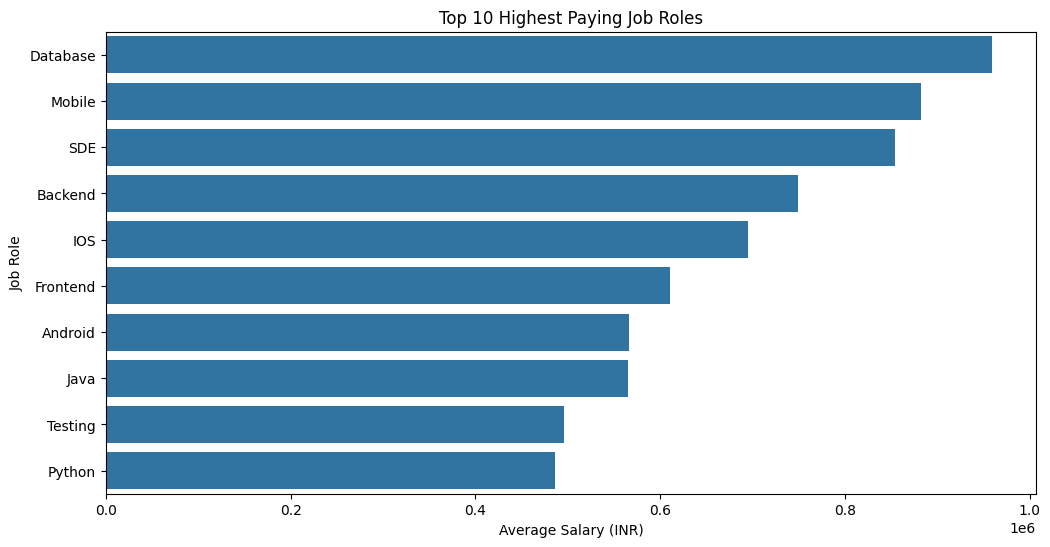

In [24]:
top_roles = job_salary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_roles["Average Salary"],
    y=top_roles.index
)

plt.title("Top 10 Highest Paying Job Roles")

plt.xlabel("Average Salary (INR)")

plt.ylabel("Job Role")

plt.show()

In [25]:
location_salary = df_clean.groupby("Location")["Salary"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

location_salary.columns = ["Average Salary", "Median Salary", "Number of Records"]

display(location_salary.head(15))

,Average Salary,Median Salary,Number of Records
Location,,,
Mumbai,961180.368491,708000.0,749
Bangalore,735344.739593,500000.0,8264
Kolkata,710925.573034,500000.0,178
Pune,690476.311153,500000.0,2134
Hyderabad,679099.157376,500000.0,4467
Madhya Pradesh,677641.909677,500000.0,155
New Delhi,658756.735632,500000.0,4176
Jaipur,629135.802469,500000.0,81
Chennai,584559.661513,400000.0,2458


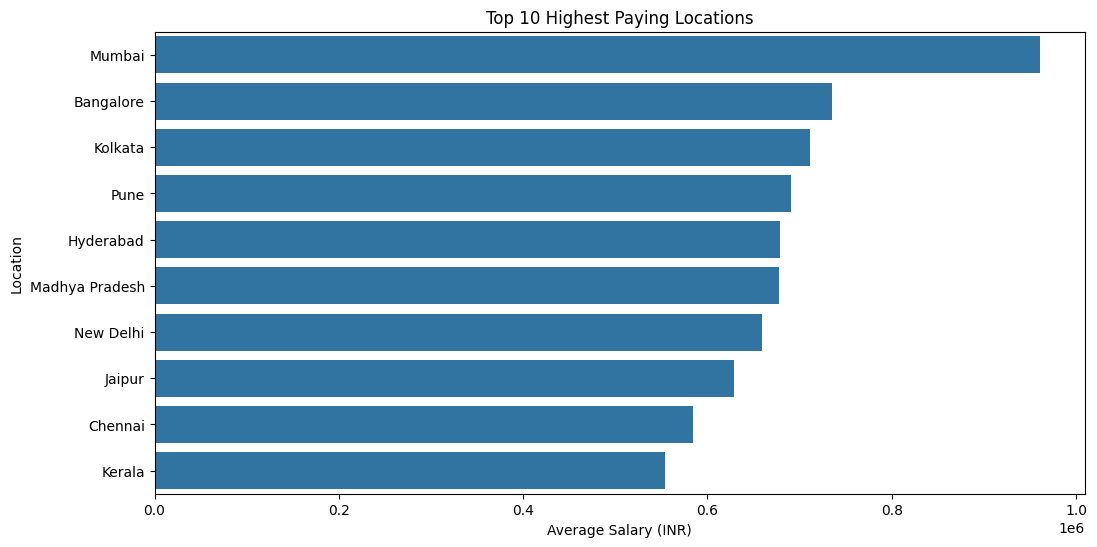

In [26]:
top_locations = location_salary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_locations["Average Salary"],
    y=top_locations.index
)

plt.title("Top 10 Highest Paying Locations")

plt.xlabel("Average Salary (INR)")

plt.ylabel("Location")

plt.show()

In [27]:
# Company Salary Analysis

company_salary = df_clean.groupby("Company Name")["Salary"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

company_salary.columns = [
    "Average Salary",
    "Median Salary",
    "Number of Records"
]

display(company_salary.head(15))

,Average Salary,Median Salary,Number of Records
Company Name,,,
Thapar University,90000000.0,90000000.0,1
FFF Enterprises,9800000.0,9800000.0,1
Digital Raju,9800000.0,9800000.0,1
Gaana Lyrics Point.com,9700000.0,9700000.0,1
GGH Heavy Industries,9600000.0,9600000.0,1
Tenneco,7700000.0,7700000.0,1
Adwitech Info Systems,7300000.0,7300000.0,1
Techware Solution,6900000.0,6900000.0,1
KH TEC,6600000.0,6600000.0,1


In [28]:
# Filter companies with at least 10 salary records

reliable_companies = company_salary[
    company_salary["Number of Records"] >= 10
]

# Top 10 companies

top_companies = reliable_companies.head(10)

display(top_companies)

,Average Salary,Median Salary,Number of Records
Company Name,,,
Gojek,2.708333e+06,2400000.0,12
Hotstar,2.398500e+06,2350000.0,16
ShareChat,2.053882e+06,1800000.0,17
Trilogy Innovations,2.044000e+06,2400000.0,11
NortonLifeLock,2.038000e+06,1650000.0,18
MindTickle,1.819529e+06,1700000.0,17
InMobi,1.788923e+06,1900000.0,13
Dream11,1.786667e+06,1500000.0,15
PhonePe,1.727600e+06,1800000.0,10


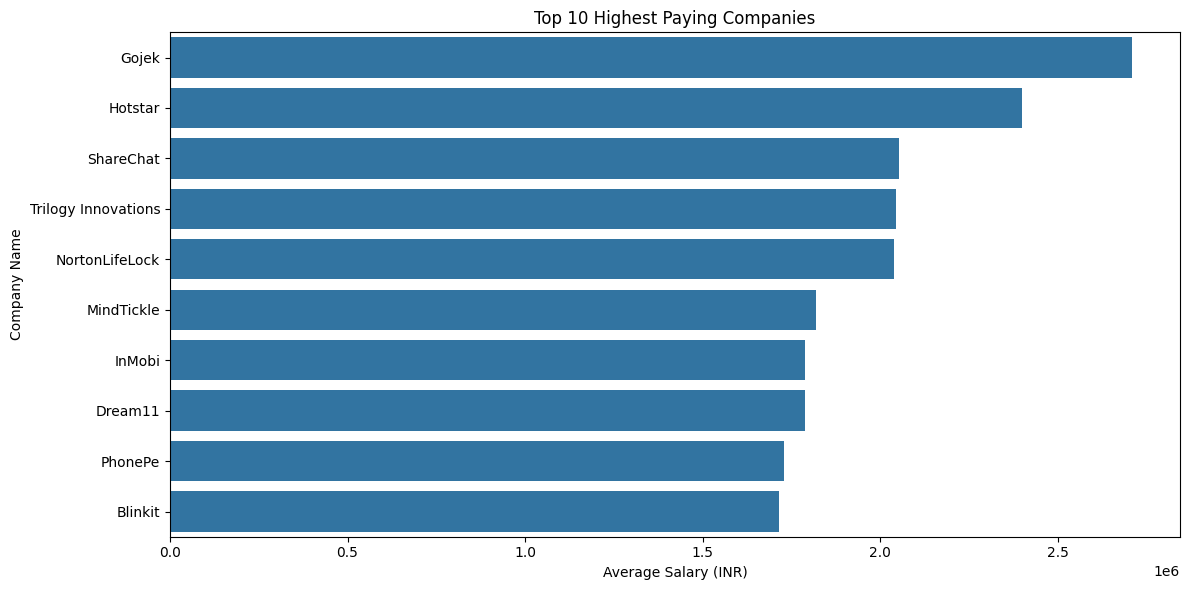

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_companies["Average Salary"],
    y=top_companies.index
)

plt.title("Top 10 Highest Paying Companies")

plt.xlabel("Average Salary (INR)")

plt.ylabel("Company Name")

plt.tight_layout()

plt.show()

In [30]:
# Employment Status Analysis

employment_salary = df_clean.groupby("Employment Status")["Salary"].agg(
    ["mean", "median", "count"]
).sort_values(by="mean", ascending=False)

employment_salary.columns = [
    "Average Salary",
    "Median Salary",
    "Number of Records"
]

display(employment_salary)

,Average Salary,Median Salary,Number of Records
Employment Status,,,
Full Time,733332.377035,500000.0,20083
Contractor,627362.364964,462000.0,548
Intern,357054.176638,276000.0,2106
Trainee,324303.030303,240000.0,33


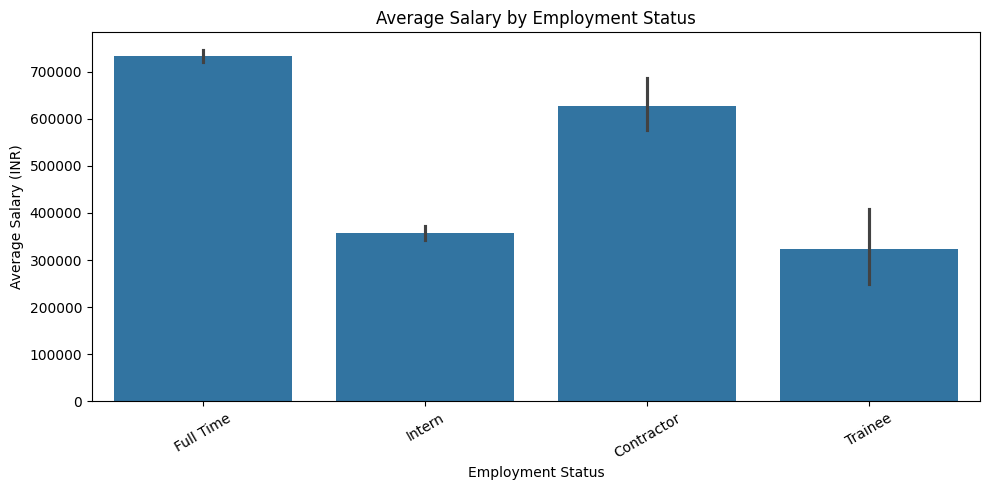

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x="Employment Status",
    y="Salary",
    estimator="mean"
)

plt.title("Average Salary by Employment Status")

plt.xlabel("Employment Status")

plt.ylabel("Average Salary (INR)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [32]:
# Companies with at least 30 salary records

reliable_companies = company_salary[
    company_salary["Number of Records"] >= 30
]

# Rank companies using median salary
top_companies_reliable = reliable_companies.sort_values(
    by="Median Salary",
    ascending=False
).head(10)

display(top_companies_reliable)

,Average Salary,Median Salary,Number of Records
Company Name,,,
Microsoft,1.444882e+06,1200000.0,96
Flipkart,1.335200e+06,1200000.0,40
Cisco Systems,1.290047e+06,1100000.0,43
Oracle,9.395692e+05,900000.0,65
Amazon,1.181223e+06,800000.0,184
Paytm,9.704762e+05,800000.0,42
Dell Technologies,8.464881e+05,800000.0,55
Publicis Sapient,8.783784e+05,708000.0,37
EPAM Systems,1.003879e+06,700000.0,33


In [33]:
# Select numerical columns

numeric_df = df_clean[
    ["Rating", "Salary", "Salaries Reported"]
]

# Calculate correlation

correlation_matrix = numeric_df.corr(method="pearson")

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Rating,Salary,Salaries Reported
Rating,1.000000,0.025476,-0.011690
Salary,0.025476,1.000000,0.004481
Salaries Reported,-0.011690,0.004481,1.000000


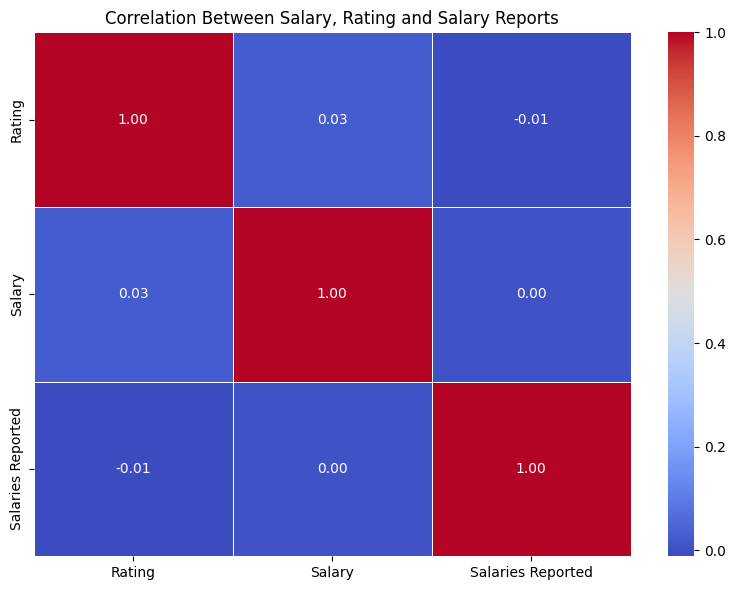

In [34]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Salary, Rating and Salary Reports")

plt.tight_layout()

plt.show()

In [35]:
spearman_corr = numeric_df.corr(method="spearman")

print("Spearman Correlation:")
display(spearman_corr)

Spearman Correlation:


,Rating,Salary,Salaries Reported
Rating,1.000000,0.020317,0.003197
Salary,0.020317,1.000000,-0.008075
Salaries Reported,0.003197,-0.008075,1.000000


In [36]:
# Separate salary groups

full_time = df_clean[
    df_clean["Employment Status"] == "Full Time"
]["Salary"]

contractor = df_clean[
    df_clean["Employment Status"] == "Contractor"
]["Salary"]

intern = df_clean[
    df_clean["Employment Status"] == "Intern"
]["Salary"]

# Perform Kruskal-Wallis test

statistic, p_value = stats.kruskal(
    full_time,
    contractor,
    intern
)

print("Kruskal-Wallis Test Results")

print("Test Statistic:", statistic)

print("P-value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Salary distributions differ significantly across groups.")
else:
    print("Fail to Reject Null Hypothesis")
    print("Insufficient evidence of a significant difference.")

Kruskal-Wallis Test Results
Test Statistic: 1310.0666330184556
P-value: 3.331541114477537e-285
Reject Null Hypothesis
Salary distributions differ significantly across groups.


In [37]:
# Use the same cleaned Kaggle dataset

X = df_clean.drop(columns=["Salary"])

y = df_clean["Salary"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (22770, 7)
Target shape: (22770,)


,Rating,Company Name,Job Title,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,3,Bangalore,Full Time,Android


0     400000
1     400000
2    1000000
3     300000
4     600000
Name: Salary, dtype: int64

In [38]:
# Identify numerical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", numerical_features)

print("Categorical Features:", categorical_features)

Numerical Features: ['Rating', 'Salaries Reported']
Categorical Features: ['Company Name', 'Job Title', 'Location', 'Employment Status', 'Job Roles']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (18216, 7)
Testing Data: (4554, 7)


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [42]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [43]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [44]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [45]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10))
])

print("Ridge Regression model created successfully!")

Ridge Regression model created successfully!


In [46]:
ridge_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [47]:
ridge_predictions = ridge_model.predict(X_test)

print("Predictions generated successfully!")

print("Actual Salaries:")
print(y_test.head(10).values)

print("\nPredicted Salaries:")
print(ridge_predictions[:10])

Predictions generated successfully!
Actual Salaries:
[800000 100000 400000 300000 500000 300000 900000 396000 300000 300000]

Predicted Salaries:
[705487.38300801 875514.4650339  527317.20103396 456206.89597301
 763784.7921238  506664.87260705 936442.50681041 452333.63575178
 497751.5005818  463684.24285124]


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, ridge_predictions)

rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))

r2 = r2_score(y_test, ridge_predictions)

print("RIDGE REGRESSION RESULTS")

print("MAE:", round(mae, 2))

print("RMSE:", round(rmse, 2))

print("R2 Score:", round(r2, 4))

RIDGE REGRESSION RESULTS
MAE: 347488.89
RMSE: 549287.11
R2 Score: 0.2559


In [49]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [54]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [52]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [53]:
rf_predictions = rf_model.predict(X_test)

print("Random Forest predictions generated!")

print("\nActual Salaries:")
print(y_test.head(10).values)

print("\nPredicted Salaries:")
print(rf_predictions[:10])

Random Forest predictions generated!

Actual Salaries:
[800000 100000 400000 300000 500000 300000 900000 396000 300000 300000]

Predicted Salaries:
[1021788.78762935  831431.39950556  538641.07449989  542969.0199423
 1016976.0469702   525896.17391411  711567.49221385  433914.54832977
  521216.06271807  432003.39457001]


In [55]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")

print("MAE:", round(rf_mae, 2))

print("RMSE:", round(rf_rmse, 2))

print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST RESULTS
MAE: 366359.14
RMSE: 585467.58
R2 Score: 0.1547


In [56]:
model_comparison = pd.DataFrame({
    "Model": ["Ridge Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

display(model_comparison)

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,347488.894509,549287.111105,0.255922
1,Random Forest,366359.140130,585467.581990,0.154672


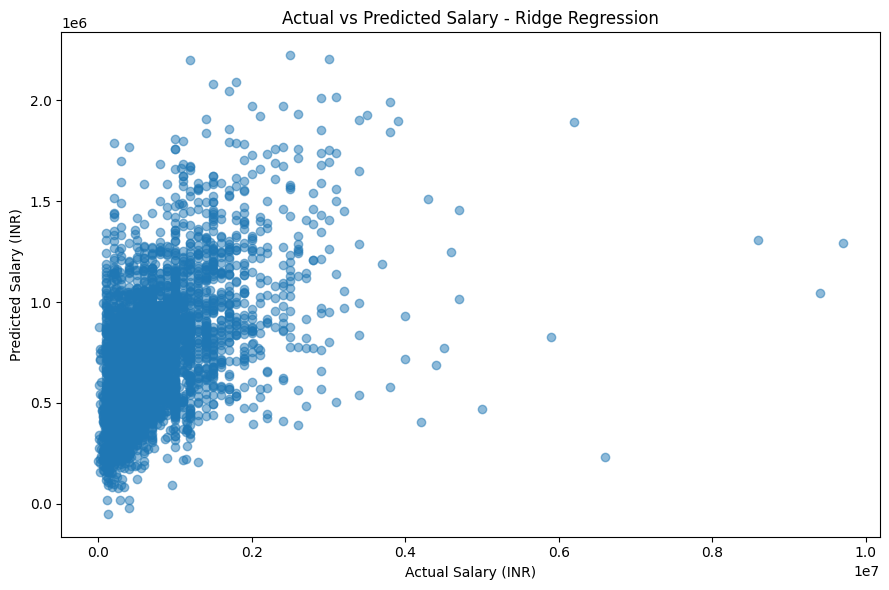

In [57]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, ridge_predictions, alpha=0.5)

plt.xlabel("Actual Salary (INR)")
plt.ylabel("Predicted Salary (INR)")

plt.title("Actual vs Predicted Salary - Ridge Regression")

plt.tight_layout()
plt.show()

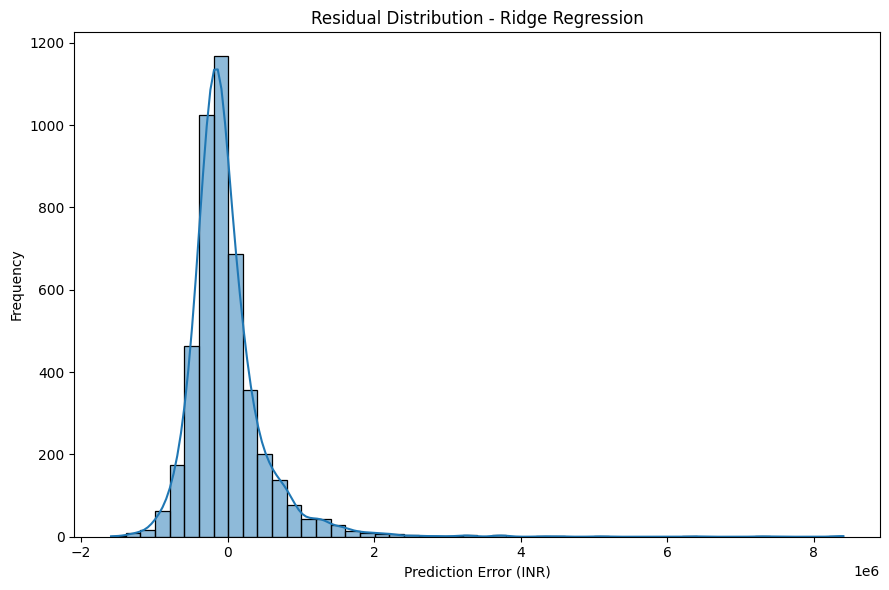

In [58]:
residuals = y_test - ridge_predictions

plt.figure(figsize=(9, 6))

sns.histplot(residuals, bins=50, kde=True)

plt.title("Residual Distribution - Ridge Regression")

plt.xlabel("Prediction Error (INR)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

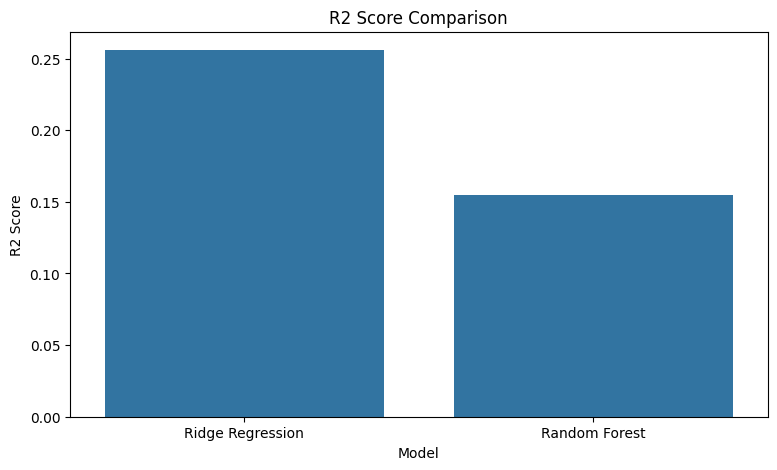

In [59]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison")

plt.ylabel("R2 Score")

plt.show()

# 📊 Business Insights and Findings

## 1. Salary Distribution Analysis

* The dataset contains 22,770 salary records.
* The average salary is approximately ₹6.95 lakh, while the median salary is ₹5 lakh.
* The average salary being higher than the median indicates a positively skewed salary distribution.
* Approximately 5.08% of salary observations are classified as outliers using the IQR method.
* Extreme salary observations can significantly influence average salary calculations.

**Business Insight:** Organizations and job seekers should consider median salary alongside average salary to understand typical compensation more accurately.

## 2. Job Role Analysis

* Database-related roles have the highest average salary among the top 10 job-role categories.
* Mobile and Software Development Engineer (SDE) roles also demonstrate comparatively high average salaries.
* Backend and iOS roles appear among the other higher-paying categories.
* Python and Testing roles have comparatively lower average salaries among the displayed top 10 categories.

**Business Insight:** Professionals can investigate specialized technical roles such as Database Engineering, Mobile Development and Software Development to understand potential compensation opportunities.

## 3. Location Analysis

* Mumbai records the highest average salary at approximately ₹9.61 lakh.
* Bangalore ranks second with an average salary of approximately ₹7.35 lakh.
* Kolkata, Pune and Hyderabad also appear among the higher-paying locations.
* Bangalore contributes the largest number of salary observations (8,264).
* Location-wise sample sizes vary considerably, which can affect the reliability of average salary comparisons.

**Business Insight:** Job seekers should compare salary opportunities across locations while considering living expenses, job availability and the number of salary observations.

## 4. Company Analysis

Considering companies with at least 30 salary records and ranking them by median salary:

* Microsoft has the highest median salary at ₹12 lakh.
* Flipkart also records a median salary of ₹12 lakh.
* Cisco Systems follows with a median salary of ₹11 lakh.
* Oracle records a median salary of ₹9 lakh.
* Amazon, Paytm and Dell Technologies each have a median salary of ₹8 lakh.

**Business Insight:** Median salary comparisons provide a more reliable starting point for evaluating company compensation than rankings based only on average salary.

## 5. Employment Status Analysis

* Full-time employees have the highest average salary of approximately ₹7.33 lakh.
* Contractors have an average salary of approximately ₹6.27 lakh.
* Interns have an average salary of approximately ₹3.57 lakh.
* Trainees have an average salary of approximately ₹3.24 lakh.
* Full-time employees account for approximately 88% of the dataset.

**Business Insight:** Employment category is an important dimension to investigate when comparing compensation structures and career opportunities.

## 6. Correlation Analysis

* Pearson correlation between company rating and salary is approximately 0.025.
* Spearman correlation between company rating and salary is approximately 0.020.
* Both indicate a very weak positive association.
* The number of salary reports also shows almost no correlation with salary.

**Business Insight:** Company ratings and salary-report counts alone do not provide meaningful information about salary variation in this dataset.

## 7. Hypothesis Testing

The Kruskal-Wallis test was performed to compare salary distributions among Full Time, Contractor and Intern employees.

Results:

* Test statistic: Approximately 1310.07.
* P-value: Approximately 3.33 × 10⁻²⁸⁵.
* Significance level: 0.05.

Since the p-value is less than 0.05, the null hypothesis is rejected.

**Business Insight:** There is statistically significant evidence that salary distributions differ among the three employment categories. Further pairwise testing is required to identify which specific groups differ.

## 8. Regression Analysis

Two regression models were evaluated using the same training and testing datasets.

| Evaluation Metric | Ridge Regression | Random Forest |
| ----------------- | ---------------: | ------------: |
| MAE               |        ₹3,47,489 |     ₹3,66,359 |
| RMSE              |        ₹5,49,287 |     ₹5,85,468 |
| R² Score          |           0.2559 |        0.1547 |

Findings:

* Ridge Regression performed better than Random Forest across all three evaluation metrics.
* Ridge Regression explained approximately 25.59% of the variation in test-set salaries.
* Random Forest explained approximately 15.47%.
* Both models have limited predictive performance.

**Business Insight:** The available dataset features have limited predictive power for salary estimation. Additional variables such as professional experience, educational qualifications and technical skills could potentially improve prediction performance.

---

# 🎯 Three Actionable Business Recommendations

### Recommendation 1: Develop Location-Based Compensation Strategies

Organizations should evaluate salary benchmarks across different cities to develop competitive compensation structures.

### Recommendation 2: Focus on Technical Skill Development

Educational institutions and job seekers should investigate specialized technical roles such as Database Engineering, Mobile Development and SDE to identify potentially rewarding career paths.

### Recommendation 3: Improve Salary Benchmarking and Prediction

Recruitment teams should use median salary benchmarks, consider employment categories and collect additional information such as experience and technical skills to improve salary estimation and compensation planning.

---

# 📝 Overall Conclusion

The analysis of 22,770 software professional salary records revealed meaningful differences in salary distributions across job roles, locations, companies and employment categories.

Exploratory data analysis identified salary patterns and extreme observations, while correlation analysis revealed weak relationships between the available numerical variables.

Hypothesis testing established statistically significant differences among employment categories. Regression modelling showed that Ridge Regression performed better than Random Forest, although both models had limited predictive accuracy.

Overall, this project demonstrates how data cleaning, exploratory data analysis, statistical testing, regression modelling and visualization can transform raw salary records into meaningful business insights and actionable recommendations.
